# Prostorová analýza uliční sítě: Staré Město (Praha)
**Autor:** Yekaterina Speshilova  
**Knihovna:** OSMnx (verze 2.1.1)  
**Semestrální projekt:** Prezentace a demonstrace vybrané prostorové knihovny v Pythonu.

## 1. Úvod a teoretický kontext
OSMnx je open-source knihovna vyvinutá Geoffem Boeingem, která propojuje data z OpenStreetMap s datovými strukturami síťového modelování NetworkX a prostorovými rámci GeoPandas.

Tradiční stahování silničních dat vyžadovalo manuální filtrování velkých shapefile souborů a složité čištění topologie. OSMnx tento proces automatizuje: 
1. Stahuje síť jedním řádkem;
2. Zjednodušuje přebytečné geometrické vrcholy;
3. Vytváří orientovaný multigraf (`MultiDiGraph`).

In [1]:
import osmnx as ox
import networkx as nx
import matplotlib.pyplot as plt

# Ověření verze knihovny a nastavení zobrazení
print(f"Použitá verze OSMnx: {ox.__version__}")

Použitá verze OSMnx: 2.1.1


## 2. Stažení a topologické zjednodušení sítě
V této části stáhneme pěší infrastrukturu pro katastrální území **Staré Město, Praha**. 

OSMnx automaticky provádí topologické zjednodušení (`simplify=True`): odstraňuje uzly, které slouží pouze pro zakřivení ulice (stupeň uzlu = 2), a ponechává pouze reálné křižovatky a slepé ulice. Délka a přesný průběh segmentů přitom zůstávají zachovány.

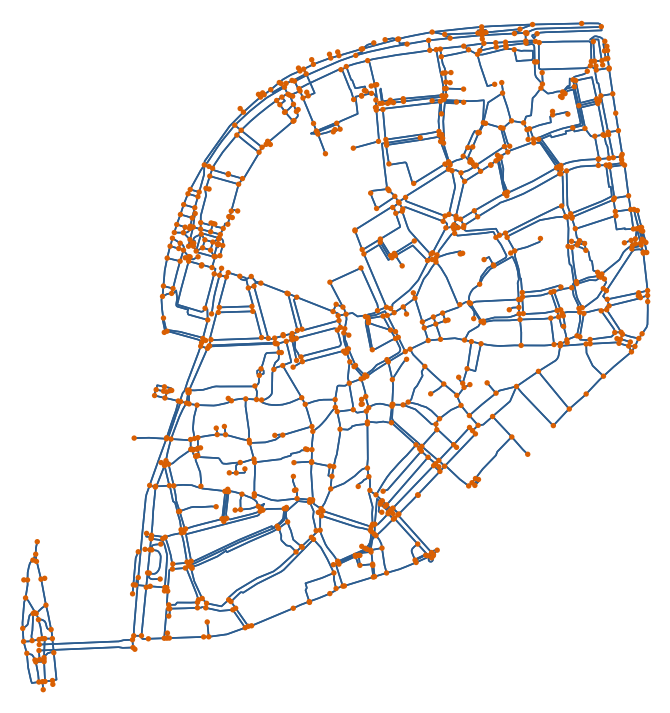

In [2]:
# Definice zájmového území
place = "Staré Město, Prague, Czechia"

# Stažení pěší sítě (network_type="walk")
G = ox.graph_from_place(place, network_type="walk")

# Základní vizualizace grafu
fig, ax = ox.plot_graph(
    G,
    node_size=15,
    node_color="#d95f02",
    edge_color="#2b5c8f",
    edge_linewidth=1.2,
    bgcolor="#ffffff",
    figsize=(9, 9)
)

## 3. Převod do GeoDataFrame a síťové metriky
Graf v NetworkX lze jednoduše rozložit na dva samostatné objekty `GeoDataFrame` knihovny GeoPandas:
- **Uzly (nodes):** křižovatky a jejich souřadnice (bodové geometrie).
- **Hrany (edges):** uliční úseky s atributy jako délka, název ulice, typ povrchu (liniové geometrie).

In [3]:
# Převod grafu na GeoDataFrames
gdf_nodes, gdf_edges = ox.graph_to_gdfs(G)

print(f"Počet křižovatek (uzlů): {len(gdf_nodes)}")
print(f"Počet uličních segmentů (hran): {len(gdf_edges)}")

# Ukázka atributů prvních 3 uličních úseků
gdf_edges[["name", "highway", "length"]].dropna().head(3)

Počet křižovatek (uzlů): 1026
Počet uličních segmentů (hran): 2746


,,,name,highway,length
u,v,key,,,
8810395,12470911326,0,Salvátorská,residential,40.305760
8810398,4601825249,0,Salvátorská,residential,50.665215
8810401,4987252774,0,Týnská ulička,living_street,10.106390


## 4. Výpočet nejkratší trasy (Routing)
Knihovna obsahuje modul `ox.routing`, který využívá Dijkstrův algoritmus implementovaný v NetworkX.

Jako modelový příklad spočítáme nejkratší pěší trasu mezi dvěma známými body:
- **Výchozí bod:** Staroměstské náměstí (orloj).
- **Cílový bod:** Vstup na Karlův most (Staroměstská mostecká věž).

Vypočtená délka pěší trasy: 709 metrů


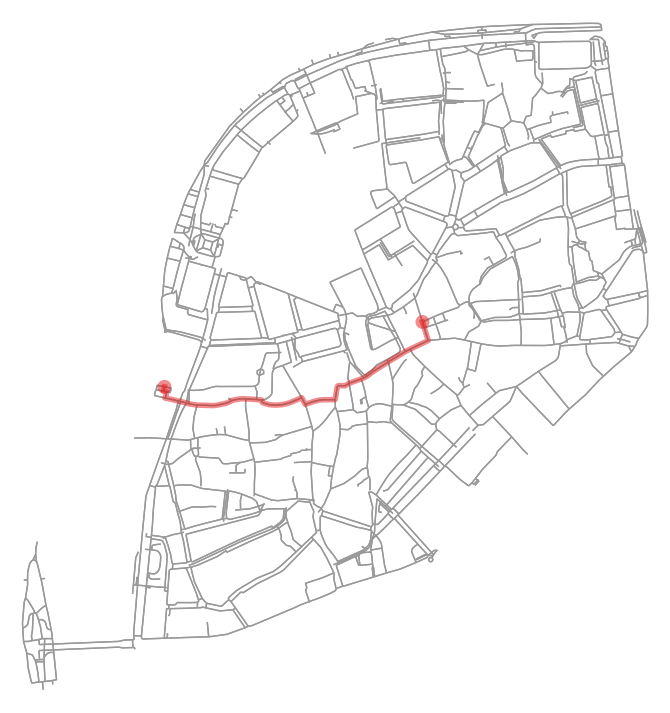

In [4]:
# Souřadnice bodů (zeměpisná šířka, délka)
staromak_coords = (50.0875, 14.4213)
karluv_most_coords = (50.0865, 14.4137)

# Nalezení nejbližších uzlů v grafu k zadaným souřadnicím
orig_node = ox.distance.nearest_nodes(G, X=staromak_coords[1], Y=staromak_coords[0])
dest_node = ox.distance.nearest_nodes(G, X=karluv_most_coords[1], Y=karluv_most_coords[0])

# Výpočet trasy s vážením podle reálné délky v metrech
route = ox.routing.shortest_path(G, orig_node, dest_node, weight="length")

# Celková délka trasy v metrech
route_length = int(nx.shortest_path_length(G, orig_node, dest_node, weight="length"))
print(f"Vypočtená délka pěší trasy: {route_length} metrů")

# Zobrazení trasy v uliční síti
fig, ax = ox.plot_graph_route(
    G, 
    route, 
    route_color="#e41a1c", 
    route_linewidth=4, 
    node_size=0, 
    bgcolor="#ffffff",
    figsize=(9, 9)
)

## 5. Stažení prostorových prvků (POIs / Features)
OSMnx neslouží pouze pro silniční sítě, ale umožňuje stahovat i polygonová a bodová data přes modul `ox.features`. Zde stáhneme historické památky a kavárny na Starém Městě.

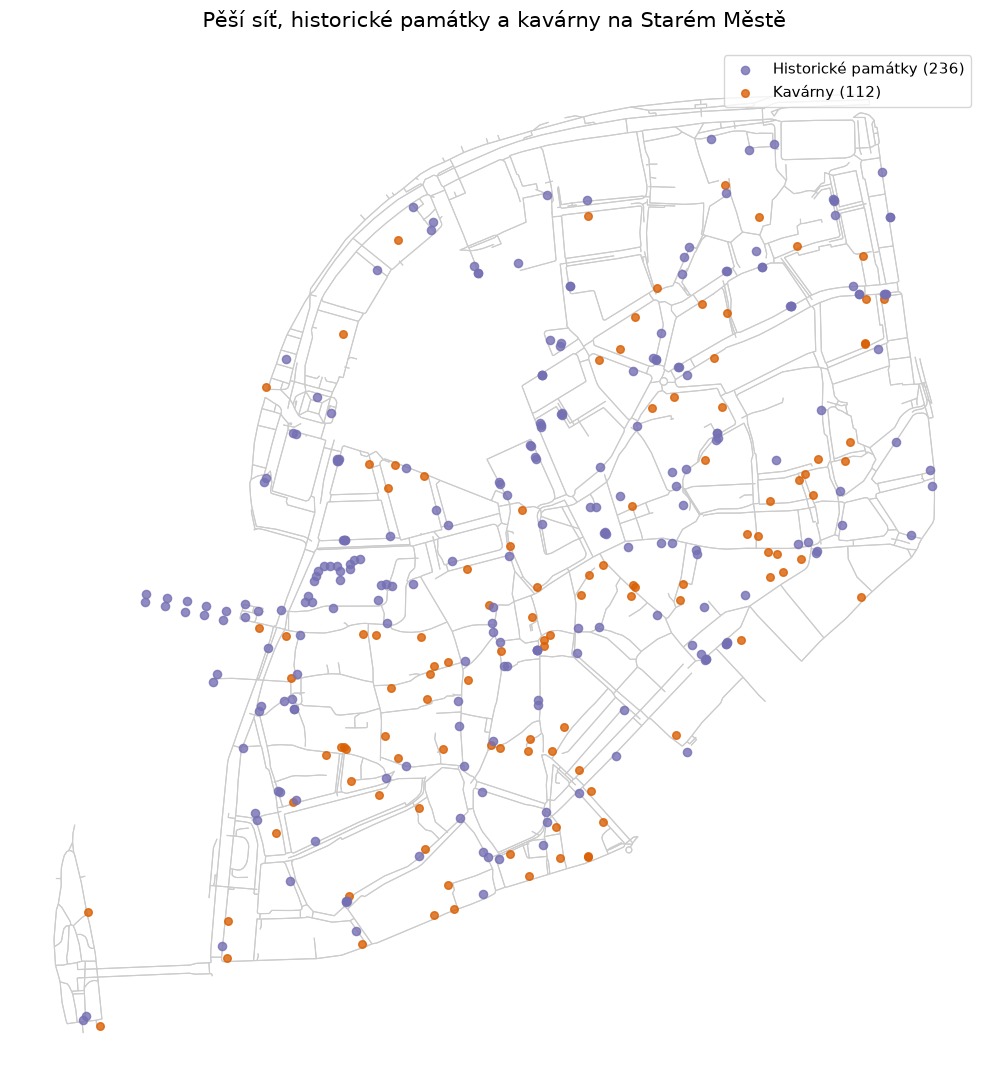

In [5]:
# 1. Nastavení zrcadla Overpass pro stabilní stažení
ox.settings.overpass_url = "https://overpass.kumi.systems/api"
ox.settings.overpass_rate_limit = False

tags = {"historic": True, "amenity": "cafe"}
pois = ox.features_from_place(place, tags=tags)

# 2. Filtrace bodových prvků a rozdělení do kategorií
pois_points = pois[pois.geometry.type == "Point"]
cafes = pois_points[pois_points["amenity"] == "cafe"]
monuments = pois_points[pois_points["historic"].notna()]

# 3. Vizualizace s oddělenými vrstvami
fig, ax = plt.subplots(figsize=(11, 11))

# Uliční síť
gdf_edges.plot(ax=ax, color="#cccccc", linewidth=0.8, zorder=1)

# Historické památky
monuments.plot(
    ax=ax,
    color="#7570b3",
    markersize=35,
    alpha=0.8,
    zorder=3,
    label=f"Historické památky ({len(monuments)})"
)

# Kavárny
cafes.plot(
    ax=ax,
    color="#d95f02",
    markersize=30,
    alpha=0.8,
    zorder=2,
    label=f"Kavárny ({len(cafes)})"
)

# Titulek a legenda v češtině
plt.title("Pěší síť, historické památky a kavárny na Starém Městě", fontsize=15, pad=15)
plt.axis("off")
plt.legend(frameon=True, facecolor="white", edgecolor="#cccccc", fontsize=11, loc="upper right")
plt.tight_layout()
plt.show()

## 6. Limity a zhodnocení knihovny
Při nasazení knihovny v praxi je nutné počítat s následujícími omezeními:
1. **Závislost na Overpass API:** Při stahování rozsáhlých regionů nebo celých států dochází k vypršení časového limitu (HTTP 504) nebo blokaci dotazu z důvodu překročení kvót serveru.
2. **Kvalita vstupních dat:** Trasa a její průchodnost plně závisí na správném otagování dobrovolníky v OSM (např. chybějící jednosměrky, soukromé pozemky, pěší zákazy).
3. **Statický model:** Knihovna sama o sobě nemodeluje dynamický provoz v reálném čase (zácpy, zpoždění na semaforech), počítá pouze statické délky a rychlostní limity.

### Závěr
OSMnx představuje ideální nástroj pro rychlý akademický výzkum, městskou morfometrii a modelování pěší dostupnosti bez nutnosti manuální přípravy prostorových vrstev.